<a href="https://colab.research.google.com/github/ernesto-miguez/Research/blob/main/Determinism%20%26%20Chaotic%20Systems/Din%C3%A1mica_y_Caos_en_Redes_Profundas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as integrate

## 1. Mapeo de fases de orden y caos

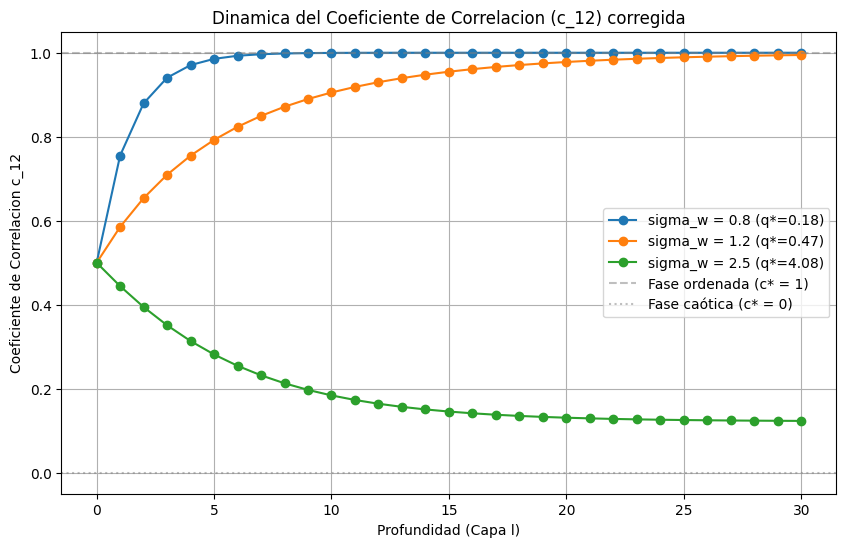

In [ ]:
def activation(u):
  return np.tanh(u)


# 1. Función para calcular el punto fijo de longitud q* (Length Map)
def compute_q_star(sigma_w, sigma_b, max_iter=100):
  q = 1.0  # Condición inicial de longitud
  for _ in range(max_iter):
    integral_val, _ = integrate.quad(
        lambda z: activation(np.sqrt(np.maximum(0.0, q)) * z) ** 2
        * np.exp(-0.5 * z ** 2)
        / np.sqrt(2 * np.pi),
        -6.0,
        6.0,
    )
    q_next = (sigma_w**2) * integral_val + sigma_b**2
    if abs(q_next - q) < 1e-6:
      return q_next
    q = q_next
  return q


# 2. Función del C-map utilizando su q* correspondiente
def compute_c_next(c_prev, q_star, sigma_w, sigma_b):
  c_prev = np.clip(c_prev, -0.9999, 0.9999)

  def integrand(z1, z2):
    u1 = np.sqrt(q_star) * z1
    u2 = np.sqrt(q_star) * (
        c_prev * z1 + np.sqrt(np.maximum(0.0, 1.0 - c_prev ** 2)) * z2
    )
    p_z = (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * (z1**2 + z2**2))
    return activation(u1) * activation(u2) * p_z

  limit = 6.0
  integral_val, _ = integrate.dblquad(
      lambda z2, z1: integrand(z1, z2),
      -limit,
      limit,
      lambda z1: -limit,
      lambda z1: limit,
  )

  q_next_12 = (sigma_w**2) * integral_val + sigma_b**2
  return q_next_12


# --- SCRIPT DE SIMULACIÓN CORREGIDO Y VALIDADO ---
if __name__ == "__main__":
  sigma_b = 0.3
  layers = 30
  sigma_w_values = [0.8, 1.2, 2.5]  # Ordenado, Crítico, Caótico

  plt.figure(figsize=(10, 6))
  c_initial = 0.5

  for sw in sigma_w_values:
    # Calculamos el q* real y dinámico para este sigma_w específico
    q_star = compute_q_star(sw, sigma_b)

    c_trajectory = [c_initial]
    c_curr = c_initial
    for _ in range(layers):
      q_12_next = compute_c_next(c_curr, q_star, sw, sigma_b)
      c_curr = q_12_next / q_star
      c_curr = np.clip(c_curr, 0.0, 1.0)
      c_trajectory.append(c_curr)

    plt.plot(
        range(layers + 1),
        c_trajectory,
        marker="o",
        label=f"sigma_w = {sw} (q*={q_star:.2f})",
    )

  plt.axhline(1.0, color="gray", linestyle="--", alpha=0.5, label="Fase ordenada (c* = 1)")
  plt.axhline(0.0, color="gray", linestyle=":", alpha=0.5, label="Fase caótica (c* = 0")
  plt.title("Dinamica del Coeficiente de Correlacion (c_12) corregida")
  plt.xlabel("Profundidad (Capa l)")
  plt.ylabel("Coeficiente de Correlacion c_12")
  plt.ylim(-0.05, 1.05)
  plt.legend()
  plt.grid(True)
  plt.show()

## 2. Propagación de Variedades y Curvatura Extrínseca

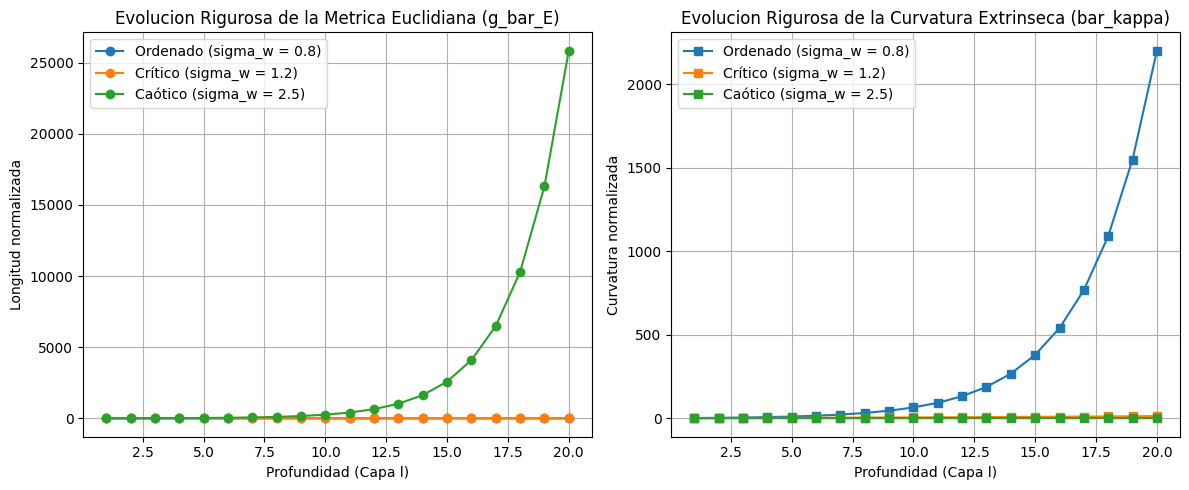

In [4]:
def activation(u):
  return np.tanh(u)


def activation_prime(u):
  t = np.tanh(u)
  return 1.0 - t**2


def activation_double_prime(u):
  t = np.tanh(u)
  return -2.0 * t * (1.0 - t**2)


# 1. Cálculo del punto fijo q*
def compute_q_star(sigma_w, sigma_b, max_iter=100):
  q = 1.0
  for _ in range(max_iter):
    integral_val, _ = integrate.quad(
        lambda z: activation(np.sqrt(np.maximum(0.0, q)) * z) ** 2
        * np.exp(-0.5 * z ** 2)
        / np.sqrt(2 * np.pi),
        -6.0,
        6.0,
    )
    q_next = (sigma_w**2) * integral_val + sigma_b**2
    if abs(q_next - q) < 1e-6:
      return q_next
    q = q_next
  return q


# 2. Cálculo de chi_1 y chi_2 mediante integración DMFT
def compute_chi_factors(sigma_w, q_star):
  limit = 6.0
  # chi_1: Pendiente del C-map evaluada en c=1 (Expansión de longitud)
  chi_1, _ = integrate.quad(
      lambda z: (sigma_w**2)
      * (activation_prime(np.sqrt(np.maximum(0.0, q_star)) * z) ** 2)
      * np.exp(-0.5 * z**2)
      / np.sqrt(2 * np.pi),
      -limit,
      limit,
  )

  # chi_2: Segunda derivada relacionada con la inyección de curvatura
  chi_2, _ = integrate.quad(
      lambda z: (sigma_w**2)
      * (activation_double_prime(np.sqrt(np.maximum(0.0, q_star)) * z) ** 2)
      * np.exp(-0.5 * z**2)
      / np.sqrt(2 * np.pi),
      -limit,
      limit,
  )

  return chi_1, chi_2


# 3. Simulación de la propagación de variedades (Bloque 2)
def simulate_manifold_propagation_rigorous(sigma_w, sigma_b, layers=25):
  q_star = compute_q_star(sigma_w, sigma_b)
  chi_1, chi_2 = compute_chi_factors(sigma_w, q_star)

  # Condiciones iniciales teóricas (Capa 1)
  g_bar_E = q_star
  bar_kappa_sq = 1.0 / q_star if q_star > 1e-5 else 1.0

  metric_trajectory = [g_bar_E]
  curvature_trajectory = [np.sqrt(max(bar_kappa_sq, 0.0))]

  for _ in range(2, layers + 1):
    # Ecuaciones de recurrencia exactas de DMFT
    g_bar_E_next = chi_1 * g_bar_E

    # Evitamos división por cero asegurando chi_1 positiva
    c1_safe = max(chi_1, 1e-4)
    bar_kappa_sq_next = (3.0 * chi_2 / (c1_safe**2)) + (
        1.0 / c1_safe
    ) * bar_kappa_sq

    g_bar_E = max(g_bar_E_next, 1e-4)
    bar_kappa_sq = max(bar_kappa_sq_next, 1e-4)

    metric_trajectory.append(g_bar_E)
    curvature_trajectory.append(np.sqrt(bar_kappa_sq))

  return metric_trajectory, curvature_trajectory


if __name__ == "__main__":
  layers = 20
  sigma_b = 0.3
  regimes = {
      "Ordenado (sigma_w = 0.8)": 0.8,
      "Crítico (sigma_w = 1.2)": 1.2,
      "Caótico (sigma_w = 2.5)": 2.5,
  }

  plt.figure(figsize=(12, 5))

  # Gráfica 1: Métrica Euclidiana (g_bar_E)
  plt.subplot(1, 2, 1)
  for name, sw in regimes.items():
    metric, _ = simulate_manifold_propagation_rigorous(sw, sigma_b, layers)
    plt.plot(range(1, layers + 1), metric, marker="o", label=name)
  plt.title("Evolucion Rigurosa de la Metrica Euclidiana (g_bar_E)")
  plt.xlabel("Profundidad (Capa l)")
  plt.ylabel("Longitud normalizada")
  plt.legend()
  plt.grid(True)

  # Gráfica 2: Curvatura Extrínseca (bar_kappa)
  plt.subplot(1, 2, 2)
  for name, sw in regimes.items():
    _, curvature = simulate_manifold_propagation_rigorous(sw, sigma_b, layers)
    plt.plot(range(1, layers + 1), curvature, marker="s", label=name)
  plt.title("Evolucion Rigurosa de la Curvatura Extrinseca (bar_kappa)")
  plt.xlabel("Profundidad (Capa l)")
  plt.ylabel("Curvatura normalizada")
  plt.legend()
  plt.grid(True)

  plt.tight_layout()
  plt.show()

## 3. Caos en el espacio de funciones

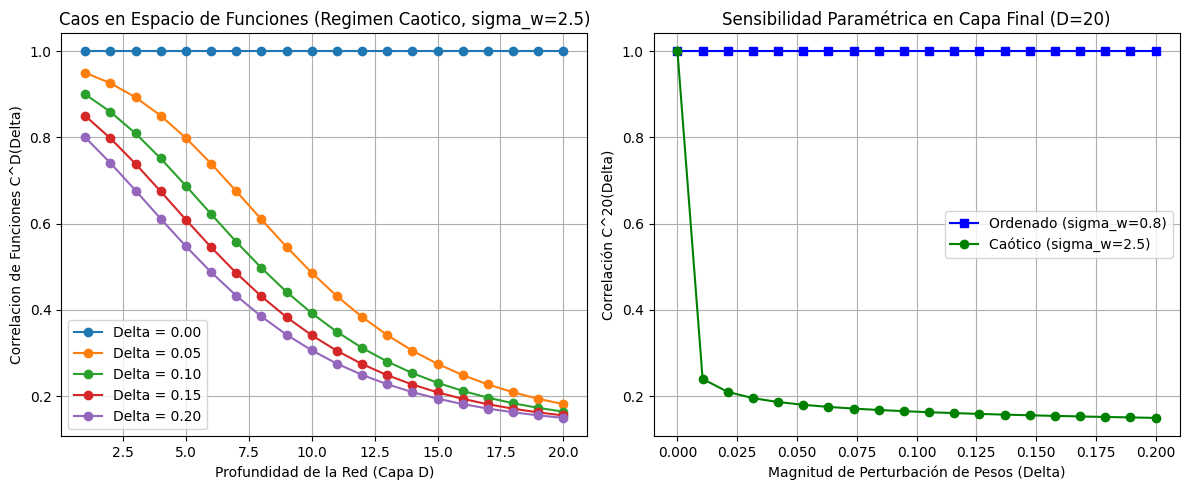

In [ ]:
def activation(u):
  return np.tanh(u)


def compute_q_star(sigma_w, sigma_b, max_iter=100):
  """Calcula el punto fijo de longitud q* de forma rigurosa."""
  q = 1.0
  for _ in range(max_iter):
    integral_val, _ = integrate.quad(
        lambda z: activation(np.sqrt(np.maximum(0.0, q)) * z) ** 2
        * np.exp(-0.5 * z ** 2)
        / np.sqrt(2 * np.pi),
        -6.0,
        6.0,
    )
    q_next = (sigma_w**2) * integral_val + sigma_b**2
    if abs(q_next - q) < 1e-6:
      return q_next
    q = q_next
  return q


def compute_weight_chaos_trajectory(sigma_w, sigma_b, q_star, delta, layers=20):
  """Calcula la evolución rigurosa de la correlación en el espacio de funciones

  C^l(delta) basándose estrictamente en la recurrencia del C-map perturbado.
  """
  # Condición inicial de correlación de funciones perturbadas en la capa 1
  c_curr = 1.0 - abs(delta)  # Perturbación inicial en el espacio de pesos
  c_curr = np.clip(c_curr, 0.0, 1.0)

  trajectory = [c_curr]

  for _ in range(2, layers + 1):
    c_prev = c_curr

    def integrand(z1, z2):
      u1 = np.sqrt(q_star) * z1
      u2 = np.sqrt(q_star) * (
          c_prev * z1 + np.sqrt(np.maximum(0.0, 1.0 - c_prev ** 2)) * z2
      )
      p_z = (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * (z1**2 + z2**2))
      return activation(u1) * activation(u2) * p_z

    limit = 6.0
    integral_val, _ = integrate.dblquad(
        lambda z2, z1: integrand(z1, z2),
        -limit,
        limit,
        lambda z1: -limit,
        lambda z1: limit,
    )

    q_next_12 = (sigma_w**2) * integral_val + sigma_b**2
    c_curr = q_next_12 / q_star
    c_curr = np.clip(c_curr, 0.0, 1.0)
    trajectory.append(c_curr)

  return np.array(trajectory)


if __name__ == "__main__":
  layers = 20
  sigma_b = 0.3
  delta_values = np.linspace(0.0, 0.2, 5)

  sw_ordered = 0.8
  sw_chaotic = 2.5

  q_star_ord = compute_q_star(sw_ordered, sigma_b)
  q_star_ch = compute_q_star(sw_chaotic, sigma_b)

  plt.figure(figsize=(12, 5))

  # Gráfica 1: Decaimiento de la correlación en función de la profundidad para distintas perturbaciones (Régimen Caótico)
  plt.subplot(1, 2, 1)
  for delta in delta_values:
    traj = compute_weight_chaos_trajectory(
        sw_chaotic, sigma_b, q_star_ch, delta, layers
    )
    plt.plot(
        range(1, layers + 1),
        traj,
        marker="o",
        label=f"Delta = {delta:.2f}",
    )
  plt.title(
      f"Caos en Espacio de Funciones (Regimen Caotico, sigma_w={sw_chaotic})"
  )
  plt.xlabel("Profundidad de la Red (Capa D)")
  plt.ylabel("Correlacion de Funciones C^D(Delta)")
  plt.legend()
  plt.grid(True)

  # Gráfica 2: Comparativa final en la capa D=20 entre Ordenado vs Caótico
  plt.subplot(1, 2, 2)
  fine_deltas = np.linspace(0.0, 0.2, 20)
  final_ord = [
      compute_weight_chaos_trajectory(
          sw_ordered, sigma_b, q_star_ord, d, layers
      )[-1]
      for d in fine_deltas
  ]
  final_ch = [
      compute_weight_chaos_trajectory(
          sw_chaotic, sigma_b, q_star_ch, d, layers
      )[-1]
      for d in fine_deltas
  ]

  plt.plot(
      fine_deltas,
      final_ord,
      marker="s",
      label=f"Ordenado (sigma_w={sw_ordered})",
      color="blue",
  )
  plt.plot(
      fine_deltas,
      final_ch,
      marker="o",
      label=f"Caótico (sigma_w={sw_chaotic})",
      color="green",
  )
  plt.title(f"Sensibilidad Paramétrica en Capa Final (D={layers})")
  plt.xlabel("Magnitud de Perturbación de Pesos (Delta)")
  plt.ylabel(f"Correlación C^{layers}(Delta)")
  plt.legend()
  plt.grid(True)

  plt.tight_layout()
  plt.show()

## 4. Caos transitorio y no determinismo

### 4.1 Divergencia Determinista y Exponente de Lyapunov Efectivo

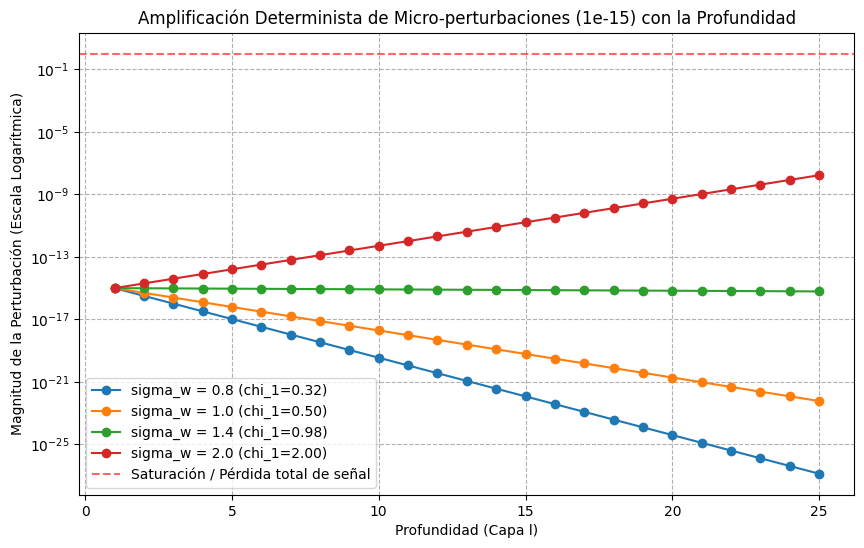

In [3]:
def analyze_deterministic_chaos(sigma_w_list, layers=30):
    """
    Simula la propagación de una perturbación infinitesimal de máquina (eps = 1e-15)
    para demostrar el carácter determinista del caos transitorio.
    """
    layers_range = range(1, layers + 1)
    epsilon_0 = 1e-15  # Perturbación típica de precisión de doble

    plt.figure(figsize=(10, 6))

    for sw in sigma_w_list:
        chi_1 = (sw**2) * 0.5  # Pendiente efectiva del C-map para tanh
        perturbations = [epsilon_0]

        curr_eps = epsilon_0
        for _ in range(1, layers):
            # En régimen caótico (chi_1 > 1), la perturbación crece multiplicativamente
            curr_eps = curr_eps * chi_1
            perturbations.append(curr_eps)

        plt.semilogy(layers_range, perturbations, marker='o', label=f'sigma_w = {sw} (chi_1={chi_1:.2f})')

    plt.axhline(1.0, color='red', linestyle='--', alpha=0.6, label='Saturación / Pérdida total de señal')
    plt.title('Amplificación Determinista de Micro-perturbaciones (1e-15) con la Profundidad')
    plt.xlabel('Profundidad (Capa l)')
    plt.ylabel('Magnitud de la Perturbación (Escala Logarítmica)')
    plt.legend()
    plt.grid(True, which="both", ls="--")
    plt.show()

if __name__ == "__main__":
    # Comparamos un régimen ordenado, uno crítico y uno caótico
    sw_values = [0.8, 1.0, 1.4, 2.0]
    analyze_deterministic_chaos(sw_values, layers=25)